#  Lab Journal

In [1]:
name            = "FBA_THB_19052026_RTD"
date            = "19.05.2026"
catalyst        = "none" 
cat_mass        = 10 * 1e-6  # kg # dummimasse


# Messpunkt capillary (MP A)
# jumo start  Uhr
# ms start Uhr

# Begleitheizung aus

# Experiment
# 1 bar absolutdruck
# Variation V_dot 


## PTK 3 Var_V_dot: 10 halbperioden a 2 min
# Strangumschaltung start x
# Temp 25°C
# V_dot_right = 62.5 # Nml/min
# V_dot_left = 62.5 # Nml/min
# V_dot_Matrix = 0 # Nml/min



# Import

In [2]:
import numpy as np
from tkinter import filedialog,messagebox
from tkinter.messagebox import askquestion
from tkinter.simpledialog import askstring,askinteger
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import os
import ICIW_Plots
plt.style.use('ICIWstyle') 
import ICIW_Plots.colors as ICIWcolors
import importlib
import matplotlib.dates as mdates
import sys
from pathlib import Path
cw_path = Path.cwd()
sys.path.append('../../../')
print(cw_path)
from datetime import timedelta
import pickle as pkl
from types import MethodType
import torch.utils
import torch.utils.data
import wandb
import lightning.pytorch as pl
from lightning.pytorch.loggers.wandb import WandbLogger
from lightning.pytorch.callbacks import LearningRateMonitor
torch.set_default_dtype(torch.float64)
sys.path.append(r"C:\Users\admin\Documents\GitHub\THA")

from FBA_ExpEval_angepasst import MS_Evaluation, Limit_cycle, dyn_meth_Anlage_semi_TPR, Data_reuse
plt.rcParams.update({'axes.labelsize': 14, 'xtick.labelsize': 12, 'ytick.labelsize': 12})


from lib.nRTD import RTDModule, RTDDataModule


c:\Users\admin\Documents\GitHub\THA\Experiments\THA_001


2026-06-24 08:41:25


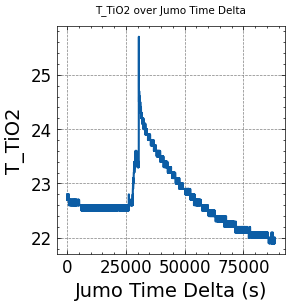

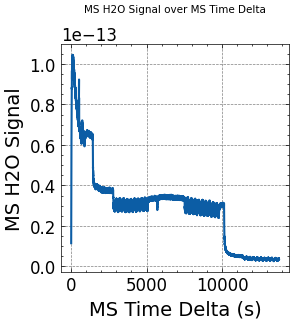

Jumo Start Time: 2026-06-24 08:41:25
MS Start Time: 2026-05-19 10:14:48.518000
Time Difference in Seconds: -3104796.482
13785.857
88351


IndexError: index 0 is out of bounds for axis 0 with size 0

In [3]:
ms_path = r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V4_vorreactor_varVdot\MS\THB_19052026_capillary_62.5Vdot_korrigiert.txt"
jumo_path = r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V4_vorreactor_varVdot\Jumo\FBA_THB_V4_vorreaktor_19052026_formatted.txt"

semiTPR = dyn_meth_Anlage_semi_TPR.semiTPR(ms_path,
                                                  jumo_path,
                                                  np.array(['time','Ar','He','H2','CO','CO2', 'CH4','H2O','C2','C3','Ne','C4','C5','C6','C2en','C3en']),
                                                  year = 2026,day_corrector=0,month_corrector=0)

# calibration

In [4]:
'''
Select Calibration Files 
'''
MS_input_filepaths = [r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V2_ges_sys_varVdot_varTemp_1barabs\kal\000_0Ar_150_0He_080_0H2_245_0H2M_000_0CO_020_0CO2_000_0CH4_000_0H2O_000_0C2_000_0C3_005_0Ne_20251024110434.txt",
r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V2_ges_sys_varVdot_varTemp_1barabs\kal\002_0Ar_155_0He_080_0H2_245_0H2M_000_0CO_000_0CO2_018_0CH4_000_0H2O_000_0C2_000_0C3_000_0Ne_20251024130537.txt",
r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V2_ges_sys_varVdot_varTemp_1barabs\kal\002_0Ar_155_0He_080_0H2_245_0H2M_018_0CO_000_0CO2_000_0CH4_000_0H2O_000_0C2_000_0C3_000_0Ne_20251024150010.txt",
r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V2_ges_sys_varVdot_varTemp_1barabs\kal\020_0Ar_110_0He_100_0H2_245_0H2M_000_0CO_025_0CO2_000_0CH4_000_0H2O_000_0C2_000_0C3_000_0Ne_20251024102824.txt"]
MS_exp_filepath = ms_path
## Bestimmung der Konzentrationen aus Kalibrierdatei
comp = np.array(['Ar','He','H2','CO','CO2', 'CH4','H2O','C2','C3','Ne','C4','C5','C6','C2en','C3en'])

In [5]:
# V_dot_reactor 62.5 nml/min V_dot_matrix 0 nml/min

kal1_class = MS_Evaluation.MKS_MS_raw_to_mole_frac(CO2_or_CO_meth='CO2', 
                                           MS_exp_file_path = MS_exp_filepath,
                                           MS_calib_file_paths = MS_input_filepaths, 
                                           comp = comp,
                                           V_dot_str_right = np.array([ 10, 52.5, 0, 0 , 0 , 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 
                                           V_dot_str_left= np.array([ 0, 62.5, 0, 0 , 0 , 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]),
                                           V_dot_Matrix = np.array([ 0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]),
                                           matrix_corr=1.2
                                           )





Used calibration file: C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V2_ges_sys_varVdot_varTemp_1barabs\kal\000_0Ar_150_0He_080_0H2_245_0H2M_000_0CO_020_0CO2_000_0CH4_000_0H2O_000_0C2_000_0C3_005_0Ne_20251024110434.txt

Volume flows during calibration:
Ar : 0.0
He : 150.0
H2 : 80.0
H2 Matrix: 245.0 * 1.2 = 294.0
H2 total: 374.0
CO : 0.0
CO2 : 20.0
CH4 : 0.0
H2O : 0.0
C2 : 0.0
C3 : 0.0
Ne : 5.0

He as reference
True
20
8

RSF 0 in %:
 ['Mass 2' 'Mass 8' 'Mass 4' 'Mass 12' 'Mass 15' 'Mass 16' 'Mass 18'
 'Mass 23' 'Mass 20' 'Mass 26' 'Mass 28' 'Mass 33' 'Mass 40' 'Mass 43'
 'Mass 44'] 
 [[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0 100   0   0   0   0   0   0   0   0   0   0   0   0]
 [125   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  46   0   0   0 653]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0 

C:\Users\admin\Documents\GitHub\THA\FBA_ExpEval_angepasst\MS_Evaluation.py:222: RuntimeWarning: invalid value encountered in divide
  RSF = np.true_divide(RSF_all.sum(0),(RSF_all!=0).sum(0))


RSF values are adjusted


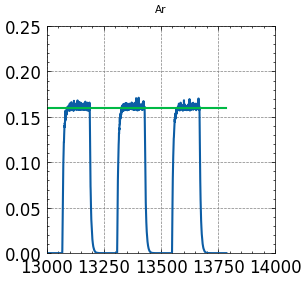

RSF_Ar_40:  5.255


In [6]:
kal1_class.calibrate_with_GC(r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V1_ges_sys_varVdot_varTemp_2barabs\GC\AZA_038__GC_Daten.npy",0, 147, 
                               t_start_GC= -2159,
                               set_x_lim_for_plot= True,
                               x_lim_low= 13000,
                               x_lim_high= 14000,
                              adj_RSF_CO2=  6.7,
                               
                              adj_RSF_CO= 70, 

                              adj_RSF_CH4= 5.7,
                              #  adj_RSF_H2O= 8,
                              adj_RSF_Ne= 0.6681,
                              adj_RSF_Ar_20=0.011,
                              adj_RSF_Ar_40=5.255,
                              )



# gesamte einzeln Plots

## Gesamtübersicht

Lade Daten...


Interpoliere Daten...
Erstelle Plots...
Fertig. Zeige Diagramm...


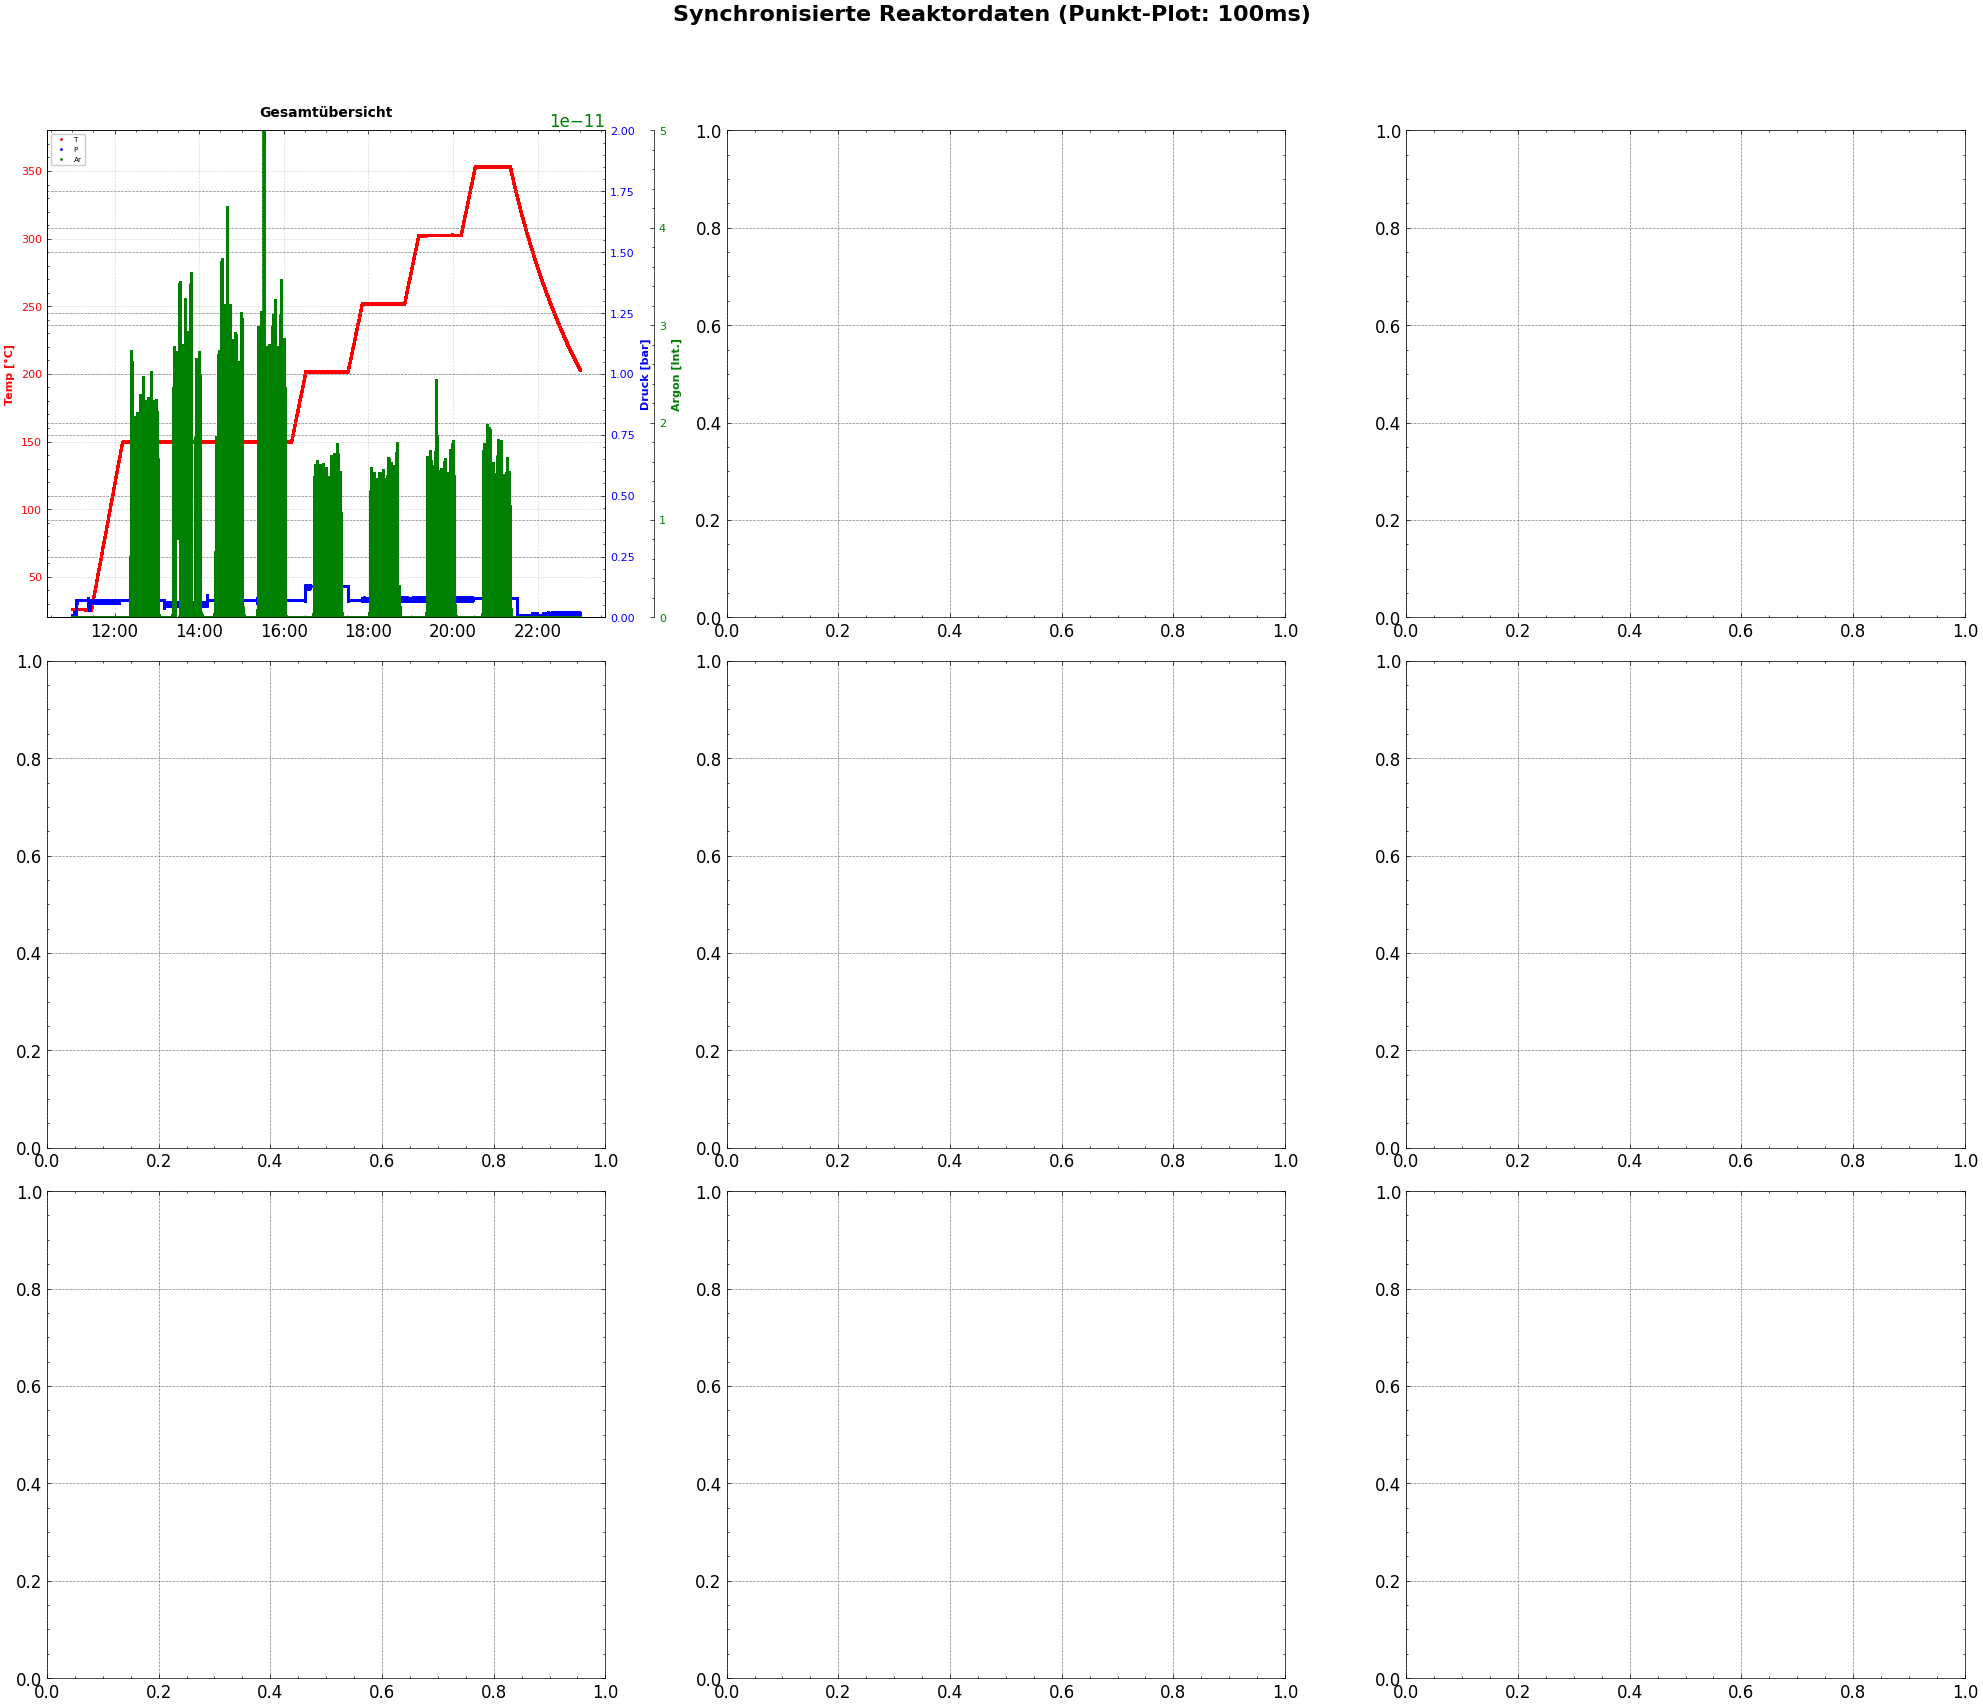

In [ ]:
# # --- EINSTELLUNGEN ---
# resample_rate = '100ms' 
# t_lim, p_lim, ar_lim = (20, 380), (0, 2), (0, 5e-11)

# # OFFSETS (z.B. um Verzögerungen in der Messstrecke auszugleichen)
# jumo_offset = timedelta(seconds=-2219)  # Hier Offset für Jumo eintragen
# ms_offset   = timedelta(seconds=0)  # Hier Offset für MS eintragen

# # Zeitphasenintervalle mit individuellen Titeln
# basis_zeitspannen = [
#     {"title": "Gesamtübersicht", "start": "05.05.2026 11:00:00", "end": "05.05.2026 23:00:00"}#,
#     # {"title": "Variation V_dot: 150°C Reactor 250 Nml/min Matrix 250 Nml/min", "start": "26.03.2026 14:11:00", "end": "26.03.2026 15:11:00"},
#     # {"title": "Variation V_dot: 150°C Reactor 125 Nml/min Matrix 250 Nml/min", "start": "26.03.2026 15:11:00", "end": "26.03.2026 16:11:00"},
#     # {"title": "Variation V_dot: 150°C Reactor 250 Nml/min Matrix 125 Nml/min", "start": "26.03.2026 16:11:00", "end": "26.03.2026 17:11:00"},
#     # {"title": "Variation V_dot: 150°C Reactor 250 Nml/min Matrix 0 Nml/min", "start": "26.03.2026 17:11:00", "end": "26.03.2026 18:11:00"},
#     # {"title": "Variation Temperatur: 200°C Reactor 250 Nml/min Matrix 250 Nml/min", "start": "26.03.2026 18:31:00", "end": "26.03.2026 19:31:00"},
#     # {"title": "Variation Temperatur: 250°C Reactor 250 Nml/min Matrix 250 Nml/min", "start": "26.03.2026 19:51:00", "end": "26.03.2026 20:51:00"},
#     # {"title": "Variation Temperatur: 300°C Reactor 250 Nml/min Matrix 250 Nml/min", "start": "26.03.2026 21:11:00", "end": "26.03.2026 22:11:00"},
#     # {"title": "Variation Temperatur: 350°C Reactor 250 Nml/min Matrix 250 Nml/min", "start": "26.03.2026 22:31:00", "end": "26.03.2026 23:31:00"}
# ]

# # Daten laden Funktion (mit Offset-Logik)
# def load_data(path, is_ms=False, offset=timedelta(0)):
#     if is_ms:
#         df = pd.read_csv(path, sep='\t', skiprows=2)
#         df['Timestamp'] = pd.to_datetime(df['Time'], dayfirst=True) + offset
#         ar_col = [c for c in df.columns if '40' in str(c)][0]
#         df = df[['Timestamp', ar_col]].rename(columns={ar_col: 'Ar'})
#     else:
#         df = pd.read_csv(path, sep='\t', skiprows=8, header=None, usecols=[1,2,3,6])
#         df.columns = ['Datum', 'Zeit', 'T_Reaktor', 'Druck']
#         df['Timestamp'] = pd.to_datetime(df['Datum'] + ' ' + df['Zeit'], dayfirst=True) + offset
#         df = df[['Timestamp', 'T_Reaktor', 'Druck']]
    
#     return df.set_index('Timestamp').sort_index()

# print("Lade Daten...")
# df_j_raw = load_data(jumo_path, is_ms=False, offset=jumo_offset)
# df_ms_raw = load_data(ms_path, is_ms=True, offset=ms_offset)

# # Interpolation & Synchronisation
# print("Interpoliere Daten...")
# full_start = min(df_j_raw.index.min(), df_ms_raw.index.min())
# full_end   = max(df_j_raw.index.max(), df_ms_raw.index.max())
# common_index = pd.date_range(start=full_start, end=full_end, freq=resample_rate)

# df_j = df_j_raw.reindex(common_index)
# df_ms = df_ms_raw.reindex(common_index)

# df_j['T_Reaktor'] = df_j['T_Reaktor'].interpolate(method='cubic')
# df_j['Druck']     = df_j['Druck'].interpolate(method='cubic')
# df_ms['Ar']       = df_ms['Ar'].interpolate(method='cubic')

# df_final = pd.concat([df_j, df_ms], axis=1).reset_index().rename(columns={'index': 'Timestamp'})

# # Plotten (angepasst auf 9 Plots: 3x3 Grid)
# print("Erstelle Plots...")
# fig, axes = plt.subplots(3, 3, figsize=(20, 18))
# axes_flat = axes.flatten()

# for i, phase in enumerate(basis_zeitspannen):
#     if i >= len(axes_flat): break
    
#     ax1 = axes_flat[i]
#     start_ts = pd.to_datetime(phase["start"])
#     end_ts   = pd.to_datetime(phase["end"])
    
#     sub = df_final[(df_final['Timestamp'] >= start_ts) & (df_final['Timestamp'] <= end_ts)].copy()
#     sub = sub.dropna(subset=['T_Reaktor', 'Druck', 'Ar'])
    
#     if sub.empty: 
#         ax1.set_title(f"{phase['title']} (Keine Daten)")
#         continue

#     # --- PLOT: Temperatur ---
#     line1, = ax1.plot(sub['Timestamp'], sub['T_Reaktor'], '.', color='red', label='T', markersize=2)
#     ax1.set_ylim(t_lim)
#     ax1.set_ylabel('Temp [°C]', color='red', fontsize=8, fontweight='bold')
#     ax1.tick_params(axis='y', labelcolor='red', labelsize=8)
    
#     # --- PLOT: Druck ---
#     ax2 = ax1.twinx()
#     line2, = ax2.plot(sub['Timestamp'], sub['Druck'], '.', color='blue', label='P', markersize=2)
#     ax2.set_ylim(p_lim)
#     ax2.set_ylabel('Druck [bar]', color='blue', fontsize=8, fontweight='bold')
#     ax2.tick_params(axis='y', labelcolor='blue', labelsize=8)
    
#     # --- PLOT: Argon ---
#     ax3 = ax1.twinx()
#     ax3.spines['right'].set_position(('outward', 35))
#     line3, = ax3.plot(sub['Timestamp'], sub['Ar'], '.', color='green', label='Ar', markersize=2)
#     ax3.set_ylim(ar_lim)
#     ax3.set_ylabel('Argon [Int.]', color='green', fontsize=8, fontweight='bold')
#     ax3.tick_params(axis='y', labelcolor='green', labelsize=8)
    
#     # Design
#     ax1.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
#     ax1.set_title(phase["title"], fontsize=10, fontweight='bold')
#     ax1.grid(True, linestyle='--', alpha=0.3)
    
#     if i == 0: 
#         ax1.legend([line1, line2, line3], ['T', 'P', 'Ar'], loc='upper left', fontsize='xx-small')

# fig.suptitle(f"Synchronisierte Reaktordaten (Punkt-Plot: {resample_rate})", fontsize=16, fontweight='bold')
# fig.tight_layout(rect=[0, 0.03, 1, 0.95])

# print("Fertig. Zeige Diagramm...")
# plt.show()

## Auswertung PTK1


Check plot to see the end of the PTK experiment - this value is end_for_averaging for function: calculate_x_avg_x_std_x_CI


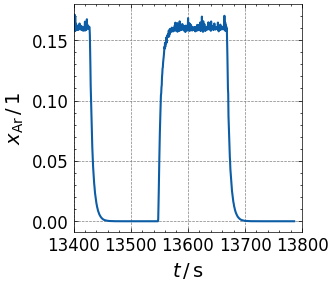

Number of averaged limit cycles 5
Number of data points in one period: 506
177
185


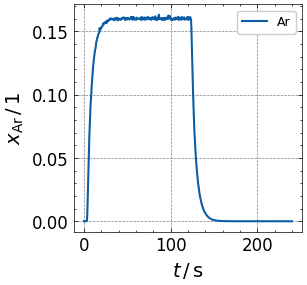

[3, 4, 5, 7, 8]
253
time for integration split:  120.23762376237623
CO2 conversion: inf, CH4 selectivity: -0.002037468808547236, CO selectivity: 1.0020374688085472
Total amount of C during the first half of the H2 Phase: 2.8990e-08 mol
Total amount of C during the second half of the COx Phase: -5.2216e-09 mol
Total amount of O during the first half of the H2 Phase: 4.6450e-07 mol
Total amount of O during the second half of the COx Phase: -4.0805e-07 mol
Total transient molar amount for Ar during H2 Phase: 3.1986e-21 mol
Total transient molar amount for Ar during COx Phase: -5.4774e-22 mol
Total transient molar amount for He during H2 Phase: 3.5986e-07 mol
Total transient molar amount for He during COx Phase: 2.2224e-08 mol
Total transient molar amount for H2 during H2 Phase: -3.4616e-07 mol
Total transient molar amount for H2 during COx Phase: -1.8599e-08 mol
Total transient molar amount for CO during H2 Phase: 2.2972e-08 mol
Total transient molar amount for CO during COx Phase: 2.2440

C:\Users\admin\Documents\GitHub\THA\FBA_ExpEval_angepasst\Limit_cycle.py:547: RuntimeWarning: invalid value encountered in divide
  self.F_i                        = (self.ni_out.T -  self.ni_qss_COx_Phase)/ (self.ni_qss_H2_Phase - self.ni_qss_COx_Phase)
C:\Users\admin\Documents\GitHub\THA\FBA_ExpEval_angepasst\Limit_cycle.py:550: RuntimeWarning: invalid value encountered in divide
  self.ni_norm                    = ((self.ni_out.T - self.ni_qss_H2_Phase)/(self.ni_qss_COx_Phase-self.ni_qss_H2_Phase)).T
C:\Users\admin\Documents\GitHub\THA\FBA_ExpEval_angepasst\Limit_cycle.py:708: RuntimeWarning: divide by zero encountered in scalar divide
  self.X_CO2 = 1 - (self.n_CO2_in - self.ni_qss_COx_Phase[self.CH4]-self.ni_qss_COx_Phase[self.CO]) / self.n_CO2_in


In [7]:
## PTK  Var_V_dot: 10 halbperioden a 2 min
# Temp 25°C
# V_dot_right = 62.5 # Nml/min
# V_dot_left = 62.5 # Nml/min
# V_dot_Matrix = 0 # Nml/min

CoTiO2_1 = Limit_cycle.generate_PTK_cycle(CO2_or_CO_meth= kal1_class.CO2_or_CO_meth, 
                                           m_cat = cat_mass, 
                                           MS_times_with_GC = kal1_class.ms_times_calib,
                                           MS_composition_with_GC = kal1_class.ms_data_calib,
                                           comp = kal1_class.comp,
                                           V_dot_str_right = kal1_class.V_dot_str_right, 
                                           V_dot_str_left= kal1_class.V_dot_str_left,
                                           V_dot_Matrix = kal1_class.V_dot_Matrix,
                                           t_COx_Phase = 120,
                                           t_H2_Phase = 120,
                                           t_switch_Ar_sig = 3.44, # check before every experiment !!!!
                                           )

CoTiO2_1.find_end_for_averaging(x_lim_low = 13400 ,x_lim_high = 13800)
CoTiO2_1.calculate_x_avg_x_std_x_CI(13700)
CoTiO2_1.cal_qss_norm_n_trans(t_qss = CoTiO2_1.t_COx_Phase-20)
#plt.plot(CoTiO2_cycle_1.t_lin,CoTiO2_cycle_1.ni_norm[CoTiO2_cycle_1.CH4])
#Data_reuse.save(CoTiO2_1, kal1_class.store_path, "data_evaluation_nocat_150°C_reactor_250_matrix_250")#Nextcloud

# Speicherpfad und dateiname
save_path = r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V4_vorreactor_varVdot\results"
file_name = "data_evaluation_nocat_cycle_25°C_capillary_1bar_reactor62.5mlmin_matrix0mlmin.npz"
full_path = os.path.join(save_path, file_name)

n_dot_Ar = CoTiO2_1.x_avg[CoTiO2_1.Ar, :]
n_dot_He = CoTiO2_1.x_avg[CoTiO2_1.He, :]
n_dot_H2 = CoTiO2_1.x_avg[CoTiO2_1.H2, :]

np.savez(full_path, 
         n_dot = [n_dot_Ar, n_dot_He, n_dot_H2], 
         time_delta=CoTiO2_1.t_lin)


# speichern der einzelnen 10er cycles

In [8]:
save_path = r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V4_vorreactor_varVdot\results"
file_name = "data_ptk_capillary_nocat_25°C_aequi_2bar_reactor63mlmin_matrix0mlmin.npz"
full_path = os.path.join(save_path, file_name)

n_dot_Ar = kal1_class.x_i[kal1_class.Ar, :]
n_dot_He = kal1_class.x_i[kal1_class.He, :]
n_dot_H2 = kal1_class.x_i[kal1_class.H2, :]

np.savez(full_path, 
         n_dot = [n_dot_Ar, n_dot_He, n_dot_H2], 
         time_delta=kal1_class.ms_exp['dt'])

# ###############################################################################################

# save_path = r"C:\Users\admin\Nextcloud\RI Herrmann\THA_V1_varVdot_varTemp\results"
# file_name = "data_evaluation_nocat_gesamt_150°C_2bar_reactor125mlmin_matrix250mlmin.npz"
# full_path = os.path.join(save_path, file_name)

# n_dot_Ar = kal2_class.x_i[kal2_class.Ar, :]
# n_dot_He = kal2_class.x_i[kal2_class.He, :]
# n_dot_H2 = kal2_class.x_i[kal2_class.H2, :]

# np.savez(full_path, 
#          n_dot = [n_dot_Ar, n_dot_He, n_dot_H2], 
#          time_delta=kal2_class.ms_exp['dt'])

# ###############################################################################################

# save_path = r"C:\Users\admin\Nextcloud\RI Herrmann\THA_V1_varVdot_varTemp\results"
# file_name = "data_evaluation_nocat_gesamt_150°C_2bar_reactor250mlmin_matrix125mlmin.npz"
# full_path = os.path.join(save_path, file_name)

# n_dot_Ar = kal3_class.x_i[kal3_class.Ar, :]
# n_dot_He = kal3_class.x_i[kal3_class.He, :]
# n_dot_H2 = kal3_class.x_i[kal3_class.H2, :]

# np.savez(full_path, 
#          n_dot = [n_dot_Ar, n_dot_He, n_dot_H2], 
#          time_delta=kal3_class.ms_exp['dt'])

# ###############################################################################################

# save_path = r"C:\Users\admin\Nextcloud\RI Herrmann\THA_V1_varVdot_varTemp\results"
# file_name = "data_evaluation_nocat_gesamt_150°C_2bar_reactor250mlmin_matrix0mlmin.npz"
# full_path = os.path.join(save_path, file_name)

# n_dot_Ar = kal4_class.x_i[kal4_class.Ar, :]
# n_dot_He = kal4_class.x_i[kal4_class.He, :]
# n_dot_H2 = kal4_class.x_i[kal4_class.H2, :]

# np.savez(full_path, 
#          n_dot = [n_dot_Ar, n_dot_He, n_dot_H2], 
#          time_delta=kal4_class.ms_exp['dt'])

# ###############################################################################################

# save_path = r"C:\Users\admin\Nextcloud\RI Herrmann\THA_V1_varVdot_varTemp\results"
# file_name = "data_evaluation_nocat_gesamt_200°C_2bar_reactor250mlmin_matrix250mlmin.npz"
# full_path = os.path.join(save_path, file_name)

# n_dot_Ar = kal5_class.x_i[kal5_class.Ar, :]
# n_dot_He = kal5_class.x_i[kal5_class.He, :]
# n_dot_H2 = kal5_class.x_i[kal5_class.H2, :]

# np.savez(full_path, 
#          n_dot = [n_dot_Ar, n_dot_He, n_dot_H2], 
#          time_delta=kal5_class.ms_exp['dt'])

# ###############################################################################################

# save_path = r"C:\Users\admin\Nextcloud\RI Herrmann\THA_V1_varVdot_varTemp\results"
# file_name = "data_evaluation_nocat_gesamt_250°C_2bar_reactor250mlmin_matrix250mlmin.npz"
# full_path = os.path.join(save_path, file_name)

# n_dot_Ar = kal6_class.x_i[kal6_class.Ar, :]
# n_dot_He = kal6_class.x_i[kal6_class.He, :]
# n_dot_H2 = kal6_class.x_i[kal6_class.H2, :]

# np.savez(full_path, 
#          n_dot = [n_dot_Ar, n_dot_He, n_dot_H2], 
#          time_delta=kal6_class.ms_exp['dt'])

# ###############################################################################################

# save_path = r"C:\Users\admin\Nextcloud\RI Herrmann\THA_V1_varVdot_varTemp\results"
# file_name = "data_evaluation_nocat_gesamt_300°C_2bar_reactor250mlmin_matrix250mlmin.npz"
# full_path = os.path.join(save_path, file_name)

# n_dot_Ar = kal7_class.x_i[kal7_class.Ar, :]
# n_dot_He = kal7_class.x_i[kal7_class.He, :]
# n_dot_H2 = kal7_class.x_i[kal7_class.H2, :]

# np.savez(full_path, 
#          n_dot = [n_dot_Ar, n_dot_He, n_dot_H2], 
#          time_delta=kal7_class.ms_exp['dt'])

# ###############################################################################################

# save_path = r"C:\Users\admin\Nextcloud\RI Herrmann\THA_V1_varVdot_varTemp\results"
# file_name = "data_evaluation_nocat_gesamt_350°C_2bar_reactor250mlmin_matrix250mlmin.npz"
# full_path = os.path.join(save_path, file_name)

# n_dot_Ar = kal8_class.x_i[kal8_class.Ar, :]
# n_dot_He = kal8_class.x_i[kal8_class.He, :]
# n_dot_H2 = kal8_class.x_i[kal8_class.H2, :]

# np.savez(full_path, 
#          n_dot = [n_dot_Ar, n_dot_He, n_dot_H2], 
#          time_delta=kal8_class.ms_exp['dt'])



#ä

Gespeichert: C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V4_vorreactor_varVdot\results\data_reactor_nocat_cycle_fehler_1bar_25grad_reactor62.5_matrix0.npz


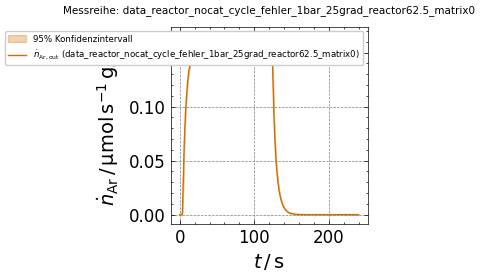

Alle Dateien erfolgreich bearbeitet.


In [ ]:
# --- KONFIGURATION ---
# 1. Liste deiner Datenobjekte (müssen im Workspace vorhanden sein)
datasets = [CoTiO2_1]

# 2. Individuelle Namen für die Speicherung (anpassbar)
custom_names = [
    "data_capillary_nocat_cycle_fehler_1bar_25grad_reactor62.5_matrix0", 
]

# 3. Speicherpfad definieren
save_path = r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V4_vorreactor_varVdot\results"
if not os.path.exists(save_path):
    os.makedirs(save_path)

# --- PLOTTING & EXPORT LOOP ---
for i, data_obj in enumerate(datasets):
    current_name = custom_names[i]
    
    # Daten extrahieren
    t = data_obj.t_lin
    y_avg = data_obj.x_avg[data_obj.Ar, :]
    ci_val = data_obj.x_CI[data_obj.Ar]
    
    y_upper = y_avg + (ci_val / 2)
    y_lower = y_avg - (ci_val / 2)

    # --- SCHRITT 1: Speichern als .npz (enthält alle Arrays) ---
    file_name = os.path.join(save_path, f"{current_name}.npz")
    np.savez(file_name, time=t, avg=y_avg, upper=y_upper, lower=y_lower)
    print(f"Gespeichert: {file_name}")

    # --- SCHRITT 2: Plotten ---
    fig = plt.figure(figsize=(16 * ICIW_Plots.cm2inch, 13 * ICIW_Plots.cm2inch))
    
    ax = ICIW_Plots.make_square_subplots(
        fig=fig,
        ax_width=5 * ICIW_Plots.cm2inch,
        ax_layout=(1, 1),
        h_sep=2 * ICIW_Plots.cm2inch,
        v_sep=1 * ICIW_Plots.cm2inch,
        sharex=False,
        sharey=False,
        sharelabel=False,
        xlabel=[r'$t\,/\,\mathrm{s}$'],
        ylabel=[[r'$\dot{n}_\mathrm{Ar}\,/\,\mathrm{ \mu mol \, s^{-1}\, g_{Co}^{-1}}$']]
    )

    # Statistischer Fehler (CI)
    ax[0, 0].fill_between(
        t,
        y1=y_upper,
        y2=y_lower,
        alpha=0.3, # Alpha auf 0.3 reduziert für bessere Sichtbarkeit der Linie
        color='#cc7000',
        label=r'95% Konfidenzintervall'
    )

    # Hauptkurve
    ax[0, 0].plot(
        t,
        y_avg,
        color='#cc7000',
        label=rf'$\dot{{n}}_\mathrm{{Ar,out}}$ ({current_name})',
        linewidth=1
    )

    # Design-Anpassungen
    ax[0, 0].set_title(f"Messreihe: {current_name}")
    ax[0, 0].legend(loc='upper right', fontsize='x-small')
    
    # Optional: Plot speichern (PNG/PDF)
    # plt.savefig(os.path.join(save_path, f"{current_name}.pdf"))
    
    plt.show()

print("Alle Dateien erfolgreich bearbeitet.")

In [ ]:
# data save als npy

save1 = {'t_lin':CoTiO2_1.t_lin, 
         'ni_out_cycle':CoTiO2_1.ni_out,
         'ni_RTD_cycle':CoTiO2_1.ni_RTD, 
         'ni_trans_cycle':CoTiO2_1.ni_trans, 
         'n_avg_bu':CoTiO2_1.ni_COx_Phase,
         'n_avg_bt':CoTiO2_1.ni_H2_Phase
         }




np.save(r'C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V4_vorreactor_varVdot\results' + r'/' + 'exp_data_evaluation_capillary_63nml-min_1bar_25grad.npy' ,save1)
